In [ ]:

import math
import random
import matplotlib.pyplot as plt

# Fix the random seed for reproducible results
random.seed(42)

# Total number of samples
N = 1000

# Number of Gaussian components in each class
K = 3

# Class 1 mixture weights
weights1 = [0.40, 0.35, 0.25]

# Class 2 mixture weights
weights2 = [0.30, 0.40, 0.30]

# Mean vectors for Class 1
means1 = [
    [-2, -3],
    [0, 0],
    [1, 4]
]

# Mean vectors for Class 2
means2 = [
    [6, -4],
    [7, 0],
    [8, 4]
]

print("PRML Assignment 6 - GMM Data Generation")
print("Samples per class:", N)
print("Gaussian components per class:", K)

print("\nClass 1 mixture weights:", weights1)
print("Class 1 means:", means1)

print("\nClass 2 mixture weights:", weights2)
print("Class 2 means:", means2)

print("\nSum of Class 1 weights:", sum(weights1))
print("Sum of Class 2 weights:", sum(weights2))


PRML Assignment 6 - GMM Data Generation
Samples per class: 1000
Gaussian components per class: 3

Class 1 mixture weights: [0.4, 0.35, 0.25]
Class 1 means: [[-2, -3], [0, 0], [1, 4]]

Class 2 mixture weights: [0.3, 0.4, 0.3]
Class 2 means: [[6, -4], [7, 0], [8, 4]]

Sum of Class 1 weights: 1.0
Sum of Class 2 weights: 1.0


In [ ]:

# STEP 2: Generate Gaussian random values using Box-Muller

def box_muller():
    # Generate two uniform random numbers
    u1 = random.random()
    u2 = random.random()

    # Avoid log(0)
    while u1 == 0:
        u1 = random.random()

    # Apply Box-Muller transformation
    radius = math.sqrt(-2 * math.log(u1))
    angle = 2 * math.pi * u2

    z1 = radius * math.cos(angle)
    z2 = radius * math.sin(angle)

    return z1, z2


# Test Box-Muller transformation
z1, z2 = box_muller()

print("Standard Normal Value Z1:", z1)
print("Standard Normal Value Z2:", z2)


Standard Normal Value Z1: 0.9340561449667306
Standard Normal Value Z2: 0.14800466463450282


In [ ]:

# STEP 3: Define covariance matrices

# ISOTROPIC COVARIANCE
# Equal variance in both dimensions

isotropic_cov1 = [
    [[1.0, 0.0], [0.0, 1.0]],
    [[1.5, 0.0], [0.0, 1.5]],
    [[1.2, 0.0], [0.0, 1.2]]
]

isotropic_cov2 = [
    [[1.2, 0.0], [0.0, 1.2]],
    [[1.0, 0.0], [0.0, 1.0]],
    [[1.5, 0.0], [0.0, 1.5]]
]


# DIAGONAL COVARIANCE
# Different variances, zero off-diagonal values

diagonal_cov1 = [
    [[2.0, 0.0], [0.0, 0.8]],
    [[0.8, 0.0], [0.0, 2.0]],
    [[1.5, 0.0], [0.0, 0.6]]
]

diagonal_cov2 = [
    [[1.0, 0.0], [0.0, 2.0]],
    [[2.0, 0.0], [0.0, 1.0]],
    [[1.5, 0.0], [0.0, 0.8]]
]


# FULL COVARIANCE
# Non-zero off-diagonal values introduce correlation

full_cov1 = [
    [[2.0, 0.8], [0.8, 1.5]],
    [[1.5, -0.6], [-0.6, 2.0]],
    [[2.0, 1.0], [1.0, 1.5]]
]

full_cov2 = [
    [[1.5, -0.7], [-0.7, 2.0]],
    [[2.0, 0.9], [0.9, 1.5]],
    [[1.5, -0.5], [-0.5, 1.0]]
]

print("All covariance matrices defined successfully!")

print("\nClass 1 - Isotropic:", isotropic_cov1)
print("\nClass 1 - Diagonal:", diagonal_cov1)
print("\nClass 1 - Full:", full_cov1)

print("\nClass 2 - Isotropic:", isotropic_cov2)
print("\nClass 2 - Diagonal:", diagonal_cov2)
print("\nClass 2 - Full:", full_cov2)


All covariance matrices defined successfully!

Class 1 - Isotropic: [[[1.0, 0.0], [0.0, 1.0]], [[1.5, 0.0], [0.0, 1.5]], [[1.2, 0.0], [0.0, 1.2]]]

Class 1 - Diagonal: [[[2.0, 0.0], [0.0, 0.8]], [[0.8, 0.0], [0.0, 2.0]], [[1.5, 0.0], [0.0, 0.6]]]

Class 1 - Full: [[[2.0, 0.8], [0.8, 1.5]], [[1.5, -0.6], [-0.6, 2.0]], [[2.0, 1.0], [1.0, 1.5]]]

Class 2 - Isotropic: [[[1.2, 0.0], [0.0, 1.2]], [[1.0, 0.0], [0.0, 1.0]], [[1.5, 0.0], [0.0, 1.5]]]

Class 2 - Diagonal: [[[1.0, 0.0], [0.0, 2.0]], [[2.0, 0.0], [0.0, 1.0]], [[1.5, 0.0], [0.0, 0.8]]]

Class 2 - Full: [[[1.5, -0.7], [-0.7, 2.0]], [[2.0, 0.9], [0.9, 1.5]], [[1.5, -0.5], [-0.5, 1.0]]]


In [ ]:

# STEP 3: Manual covariance transformation
# No NumPy random generation or built-in Cholesky

def transform_gaussian(z1, z2, mean, covariance):

    a = covariance[0][0]
    b = covariance[0][1]
    d = covariance[1][1]

    # Validate the covariance matrix
    if covariance[1][0] != b:
        raise ValueError("Covariance matrix must be symmetric")

    if a <= 0 or (a * d - b * b) <= 0:
        raise ValueError("Covariance must be positive definite")

    # Manual 2x2 transformation
    l11 = math.sqrt(a)
    l21 = b / l11
    l22 = math.sqrt(d - l21 * l21)

    # Transform standard normal values
    x1 = mean[0] + l11 * z1
    x2 = mean[1] + l21 * z1 + l22 * z2

    return [x1, x2]


# Test using one Gaussian component
z1, z2 = box_muller()

point = transform_gaussian(
    z1,
    z2,
    means1[0],
    full_cov1[0]
)

print("Generated 2D Gaussian Point:", point)


Generated 2D Gaussian Point: [-1.619319665939214, -1.1269810106395717]


In [ ]:

# STEP 4: Select a Gaussian component using mixture weights

def select_component(weights):

    r = random.random()

    if r < weights[0]:
        component = 0

    elif r < weights[0] + weights[1]:
        component = 1

    else:
        component = 2

    return component


# Test component selection
print("Class 1 selected component:", select_component(weights1))
print("Class 2 selected component:", select_component(weights2))


Class 1 selected component: 1
Class 2 selected component: 1


In [ ]:

# STEP 4: Generate complete 2D Gaussian mixture data

def generate_gmm_data(n, weights, means, covariances):

    data = []
    component_labels = []

    for i in range(n):

        # Select Gaussian component
        component = select_component(weights)

        # Generate standard normal random values
        z1, z2 = box_muller()

        # Select the corresponding mean and covariance
        mean = means[component]
        covariance = covariances[component]

        # Generate the 2D Gaussian point
        point = transform_gaussian(
            z1, z2, mean, covariance
        )

        # Store the result
        data.append(point)
        component_labels.append(component)

    return data, component_labels


# Generate Class 1 and Class 2 for all covariance types

iso_data1, iso_labels1 = generate_gmm_data(
    N, weights1, means1, isotropic_cov1
)

iso_data2, iso_labels2 = generate_gmm_data(
    N, weights2, means2, isotropic_cov2
)

diag_data1, diag_labels1 = generate_gmm_data(
    N, weights1, means1, diagonal_cov1
)

diag_data2, diag_labels2 = generate_gmm_data(
    N, weights2, means2, diagonal_cov2
)

full_data1, full_labels1 = generate_gmm_data(
    N, weights1, means1, full_cov1
)

full_data2, full_labels2 = generate_gmm_data(
    N, weights2, means2, full_cov2
)

print("Gaussian mixture data generated successfully!")

print("\nIsotropic:")
print("Class 1:", len(iso_data1), "points")
print("Class 2:", len(iso_data2), "points")

print("\nDiagonal:")
print("Class 1:", len(diag_data1), "points")
print("Class 2:", len(diag_data2), "points")

print("\nFull Covariance:")
print("Class 1:", len(full_data1), "points")
print("Class 2:", len(full_data2), "points")


Gaussian mixture data generated successfully!

Isotropic:
Class 1: 1000 points
Class 2: 1000 points

Diagonal:
Class 1: 1000 points
Class 2: 1000 points

Full Covariance:
Class 1: 1000 points
Class 2: 1000 points


In [ ]:

# Count the samples generated by each Gaussian component

print("Class 1 Isotropic Component Counts:")

for k in range(K):
    count = iso_labels1.count(k)
    print("Component", k + 1, ":", count)


print("\nClass 2 Isotropic Component Counts:")

for k in range(K):
    count = iso_labels2.count(k)
    print("Component", k + 1, ":", count)


Class 1 Isotropic Component Counts:
Component 1 : 379
Component 2 : 341
Component 3 : 280

Class 2 Isotropic Component Counts:
Component 1 : 270
Component 2 : 429
Component 3 : 301


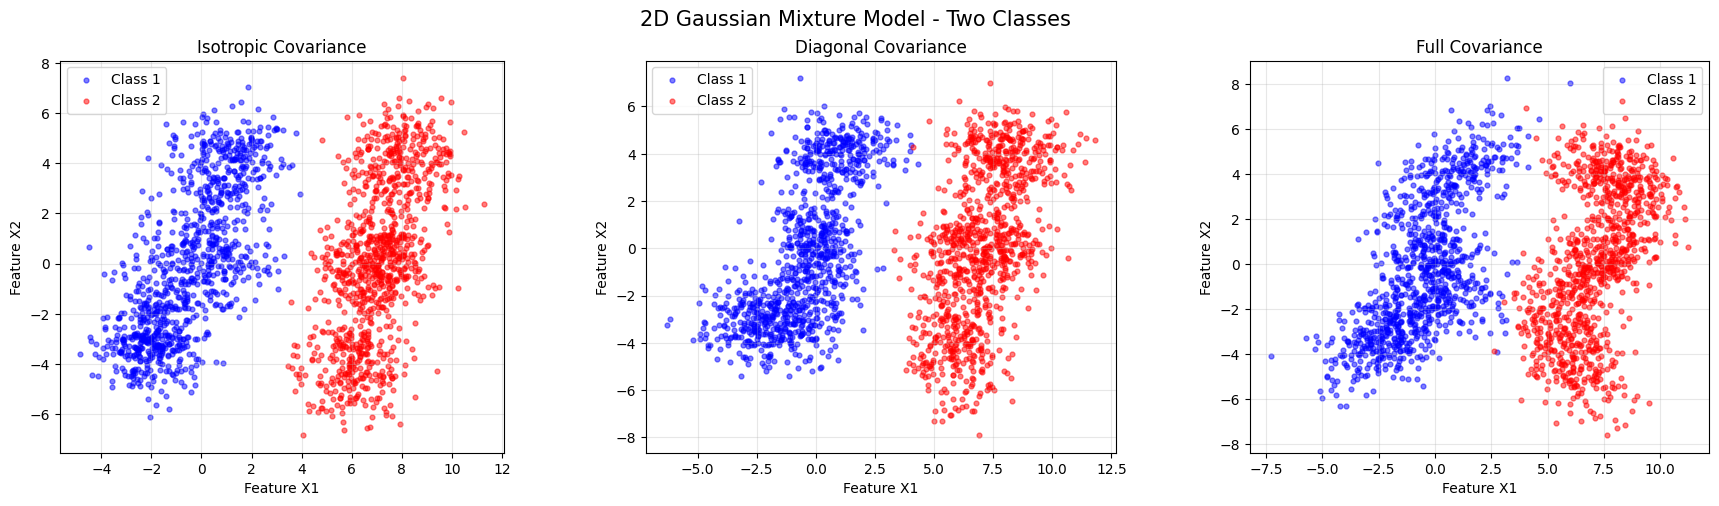

In [ ]:

# STEP 5: Visualize the generated GMM data

datasets = [
    ("Isotropic Covariance", iso_data1, iso_data2),
    ("Diagonal Covariance", diag_data1, diag_data2),
    ("Full Covariance", full_data1, full_data2)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (title, class1, class2) in zip(axes, datasets):

    # Extract x and y coordinates for Class 1
    x1 = [point[0] for point in class1]
    y1 = [point[1] for point in class1]

    # Extract x and y coordinates for Class 2
    x2 = [point[0] for point in class2]
    y2 = [point[1] for point in class2]

    # Plot Class 1
    ax.scatter(
        x1, y1,
        color="blue",
        alpha=0.5,
        s=12,
        label="Class 1"
    )

    # Plot Class 2
    ax.scatter(
        x2, y2,
        color="red",
        alpha=0.5,
        s=12,
        label="Class 2"
    )

    ax.set_title(title)
    ax.set_xlabel("Feature X1")
    ax.set_ylabel("Feature X2")
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

plt.suptitle("2D Gaussian Mixture Model - Two Classes", fontsize=15)
plt.tight_layout()
plt.show()


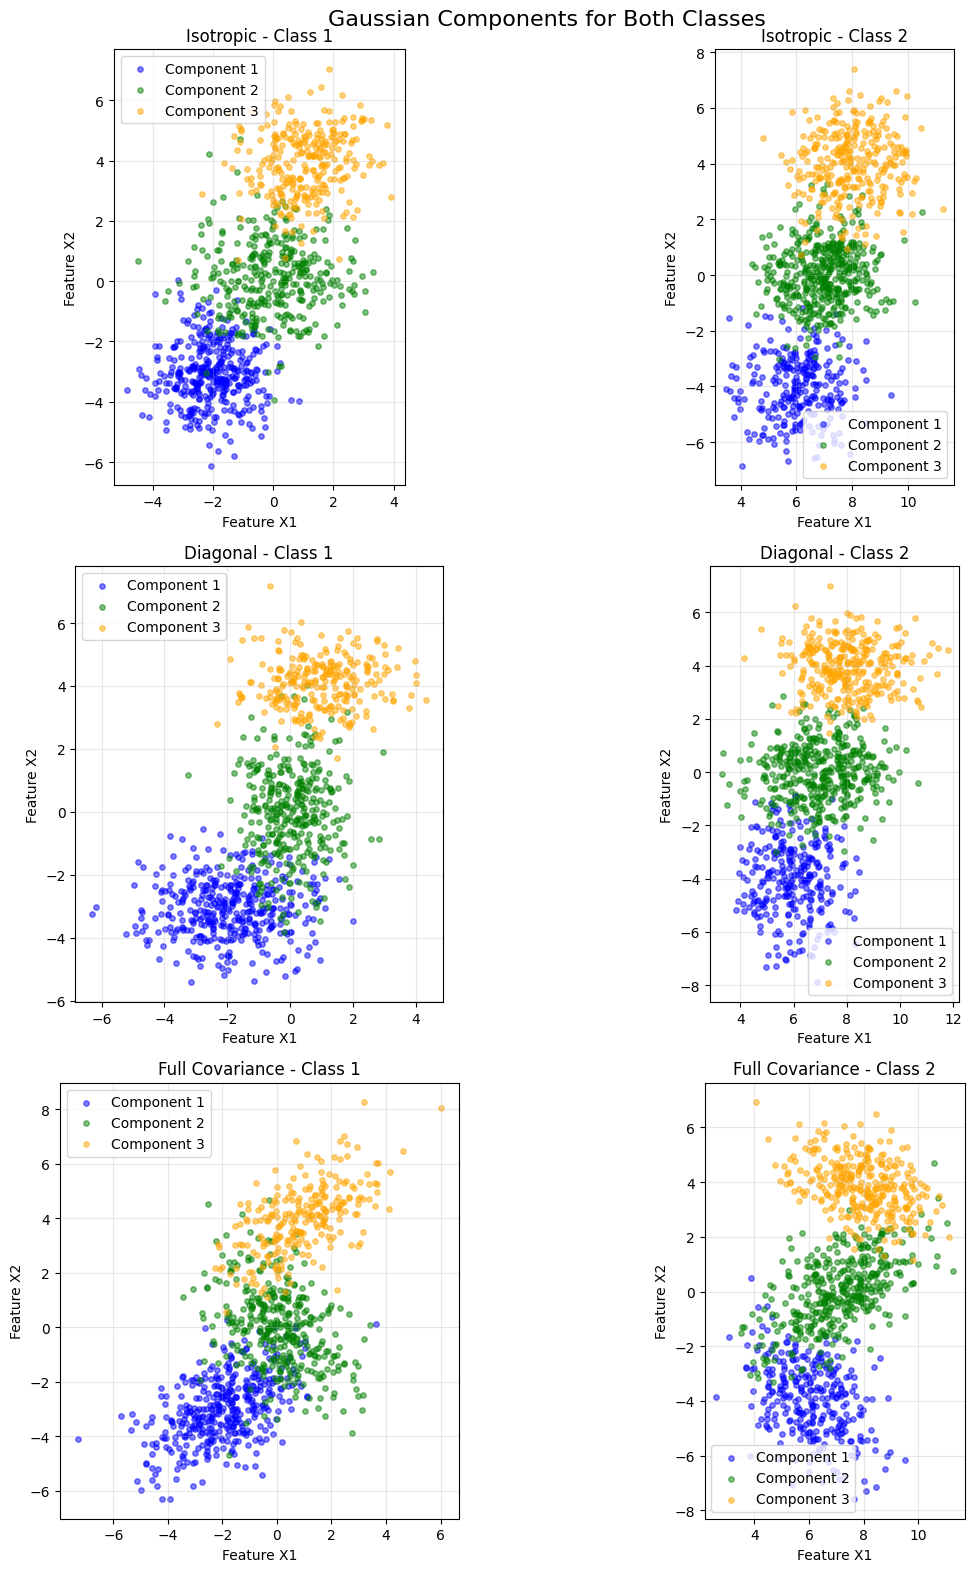

In [ ]:

# STEP 5: Plot the individual Gaussian components

component_datasets = [
    ("Isotropic", iso_data1, iso_labels1,
     iso_data2, iso_labels2),

    ("Diagonal", diag_data1, diag_labels1,
     diag_data2, diag_labels2),

    ("Full Covariance", full_data1, full_labels1,
     full_data2, full_labels2)
]

colors = ["blue", "green", "orange"]

fig, axes = plt.subplots(3, 2, figsize=(13, 16))

for row, (name, data1, labels1, data2, labels2) in enumerate(
    component_datasets
):

    for col, (data, labels) in enumerate([
        (data1, labels1),
        (data2, labels2)
    ]):

        ax = axes[row][col]

        for k in range(K):

            points = [
                data[i]
                for i in range(len(data))
                if labels[i] == k
            ]

            x = [p[0] for p in points]
            y = [p[1] for p in points]

            ax.scatter(
                x, y,
                color=colors[k],
                alpha=0.5,
                s=15,
                label="Component " + str(k + 1)
            )

        ax.set_title(name + " - Class " + str(col + 1))
        ax.set_xlabel("Feature X1")
        ax.set_ylabel("Feature X2")
        ax.legend()
        ax.grid(alpha=0.3)
        ax.set_aspect("equal", adjustable="box")

plt.suptitle(
    "Gaussian Components for Both Classes",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [ ]:

# STEP 6: Split data into 80% training and 20% testing

def train_test_split_manual(data, train_ratio=0.8):

    # Create a copy to preserve the original dataset
    shuffled_data = data.copy()

    # Randomly shuffle data points
    random.shuffle(shuffled_data)

    # Calculate number of training samples
    train_size = int(len(shuffled_data) * train_ratio)

    # Split data
    train_data = shuffled_data[:train_size]
    test_data = shuffled_data[train_size:]

    return train_data, test_data


# ISOTROPIC COVARIANCE

iso_train1, iso_test1 = train_test_split_manual(iso_data1)
iso_train2, iso_test2 = train_test_split_manual(iso_data2)


# DIAGONAL COVARIANCE

diag_train1, diag_test1 = train_test_split_manual(diag_data1)
diag_train2, diag_test2 = train_test_split_manual(diag_data2)


# FULL COVARIANCE

full_train1, full_test1 = train_test_split_manual(full_data1)
full_train2, full_test2 = train_test_split_manual(full_data2)


print("Dataset successfully divided into 80% training and 20% testing")

print("\nIsotropic Covariance:")
print("Class 1:", len(iso_train1), "Train,", len(iso_test1), "Test")
print("Class 2:", len(iso_train2), "Train,", len(iso_test2), "Test")

print("\nDiagonal Covariance:")
print("Class 1:", len(diag_train1), "Train,", len(diag_test1), "Test")
print("Class 2:", len(diag_train2), "Train,", len(diag_test2), "Test")

print("\nFull Covariance:")
print("Class 1:", len(full_train1), "Train,", len(full_test1), "Test")
print("Class 2:", len(full_train2), "Train,", len(full_test2), "Test")


Dataset successfully divided into 80% training and 20% testing

Isotropic Covariance:
Class 1: 800 Train, 200 Test
Class 2: 800 Train, 200 Test

Diagonal Covariance:
Class 1: 800 Train, 200 Test
Class 2: 800 Train, 200 Test

Full Covariance:
Class 1: 800 Train, 200 Test
Class 2: 800 Train, 200 Test


In [ ]:

# STEP 7: Manual K-Means Clustering
# No sklearn KMeans or NumPy clustering functions

def euclidean_distance_squared(p1, p2):
    return ((p1[0] - p2[0]) ** 2 +
            (p1[1] - p2[1]) ** 2)


def kmeans_manual(data, k=3, max_iterations=100, tolerance=1e-6):

    # Initialize centroids from actual training data points
    centroids = [
        point.copy()
        for point in random.sample(data, k)
    ]

    for iteration in range(max_iterations):

        # Create empty clusters
        clusters = [[] for _ in range(k)]

        # STEP A: Assign each point to nearest centroid
        for point in data:

            distances = [
                euclidean_distance_squared(point, centroid)
                for centroid in centroids
            ]

            nearest_cluster = distances.index(min(distances))
            clusters[nearest_cluster].append(point)

        # STEP B: Calculate updated centroids
        new_centroids = []

        for j in range(k):

            if len(clusters[j]) > 0:

                mean_x = sum(p[0] for p in clusters[j]) / len(clusters[j])
                mean_y = sum(p[1] for p in clusters[j]) / len(clusters[j])

                new_centroids.append([mean_x, mean_y])

            else:
                # Retain centroid if cluster is empty
                new_centroids.append(centroids[j].copy())

        # STEP C: Check convergence
        max_shift = max(
            euclidean_distance_squared(
                centroids[j], new_centroids[j]
            )
            for j in range(k)
        )

        centroids = new_centroids

        if max_shift < tolerance ** 2:
            break

    # Assign final cluster labels using final centroids
    labels = []

    for point in data:

        distances = [
            euclidean_distance_squared(point, centroid)
            for centroid in centroids
        ]

        labels.append(distances.index(min(distances)))

    # Calculate total K-Means distortion
    distortion = 0

    for point, label in zip(data, labels):
        distortion += euclidean_distance_squared(
            point, centroids[label]
        )

    return centroids, labels, distortion, iteration + 1


print("Manual K-Means algorithm defined successfully!")


Manual K-Means algorithm defined successfully!


In [ ]:

# Run K-Means separately for both classes

# ISOTROPIC
iso_centroids1, iso_cluster_labels1, iso_distortion1, iso_iter1 = kmeans_manual(
    iso_train1, K
)

iso_centroids2, iso_cluster_labels2, iso_distortion2, iso_iter2 = kmeans_manual(
    iso_train2, K
)


# DIAGONAL
diag_centroids1, diag_cluster_labels1, diag_distortion1, diag_iter1 = kmeans_manual(
    diag_train1, K
)

diag_centroids2, diag_cluster_labels2, diag_distortion2, diag_iter2 = kmeans_manual(
    diag_train2, K
)


# FULL COVARIANCE
full_centroids1, full_cluster_labels1, full_distortion1, full_iter1 = kmeans_manual(
    full_train1, K
)

full_centroids2, full_cluster_labels2, full_distortion2, full_iter2 = kmeans_manual(
    full_train2, K
)


# Display learned centroids
results = [
    ("Isotropic - Class 1", iso_centroids1, iso_distortion1, iso_iter1),
    ("Isotropic - Class 2", iso_centroids2, iso_distortion2, iso_iter2),
    ("Diagonal - Class 1", diag_centroids1, diag_distortion1, diag_iter1),
    ("Diagonal - Class 2", diag_centroids2, diag_distortion2, diag_iter2),
    ("Full - Class 1", full_centroids1, full_distortion1, full_iter1),
    ("Full - Class 2", full_centroids2, full_distortion2, full_iter2)
]

for name, centroids, distortion, iterations in results:

    print("\n", name)
    print("Iterations:", iterations)
    print("Training distortion:", round(distortion, 4))

    for i, centroid in enumerate(centroids):
        print(
            "Centroid", i + 1, ":",
            [round(v, 3) for v in centroid]
        )



 Isotropic - Class 1
Iterations: 11
Training distortion: 1782.7088
Centroid 1 : [0.973, 3.89]
Centroid 2 : [-2.014, -3.059]
Centroid 3 : [0.046, 0.108]

 Isotropic - Class 2
Iterations: 9
Training distortion: 1797.8098
Centroid 1 : [6.939, -0.032]
Centroid 2 : [8.007, 4.051]
Centroid 3 : [6.002, -4.054]

 Diagonal - Class 1
Iterations: 13
Training distortion: 1871.7647
Centroid 1 : [0.921, 3.949]
Centroid 2 : [-1.97, -3.13]
Centroid 3 : [0.078, -0.279]

 Diagonal - Class 2
Iterations: 11
Training distortion: 2097.0711
Centroid 1 : [5.957, -4.169]
Centroid 2 : [6.886, -0.104]
Centroid 3 : [8.164, 3.843]

 Full - Class 1
Iterations: 12
Training distortion: 2393.8708
Centroid 1 : [-2.331, -3.327]
Centroid 2 : [0.035, -0.376]
Centroid 3 : [0.944, 4.069]

 Full - Class 2
Iterations: 14
Training distortion: 2226.1443
Centroid 1 : [5.965, -3.836]
Centroid 2 : [7.188, 0.049]
Centroid 3 : [8.075, 3.772]


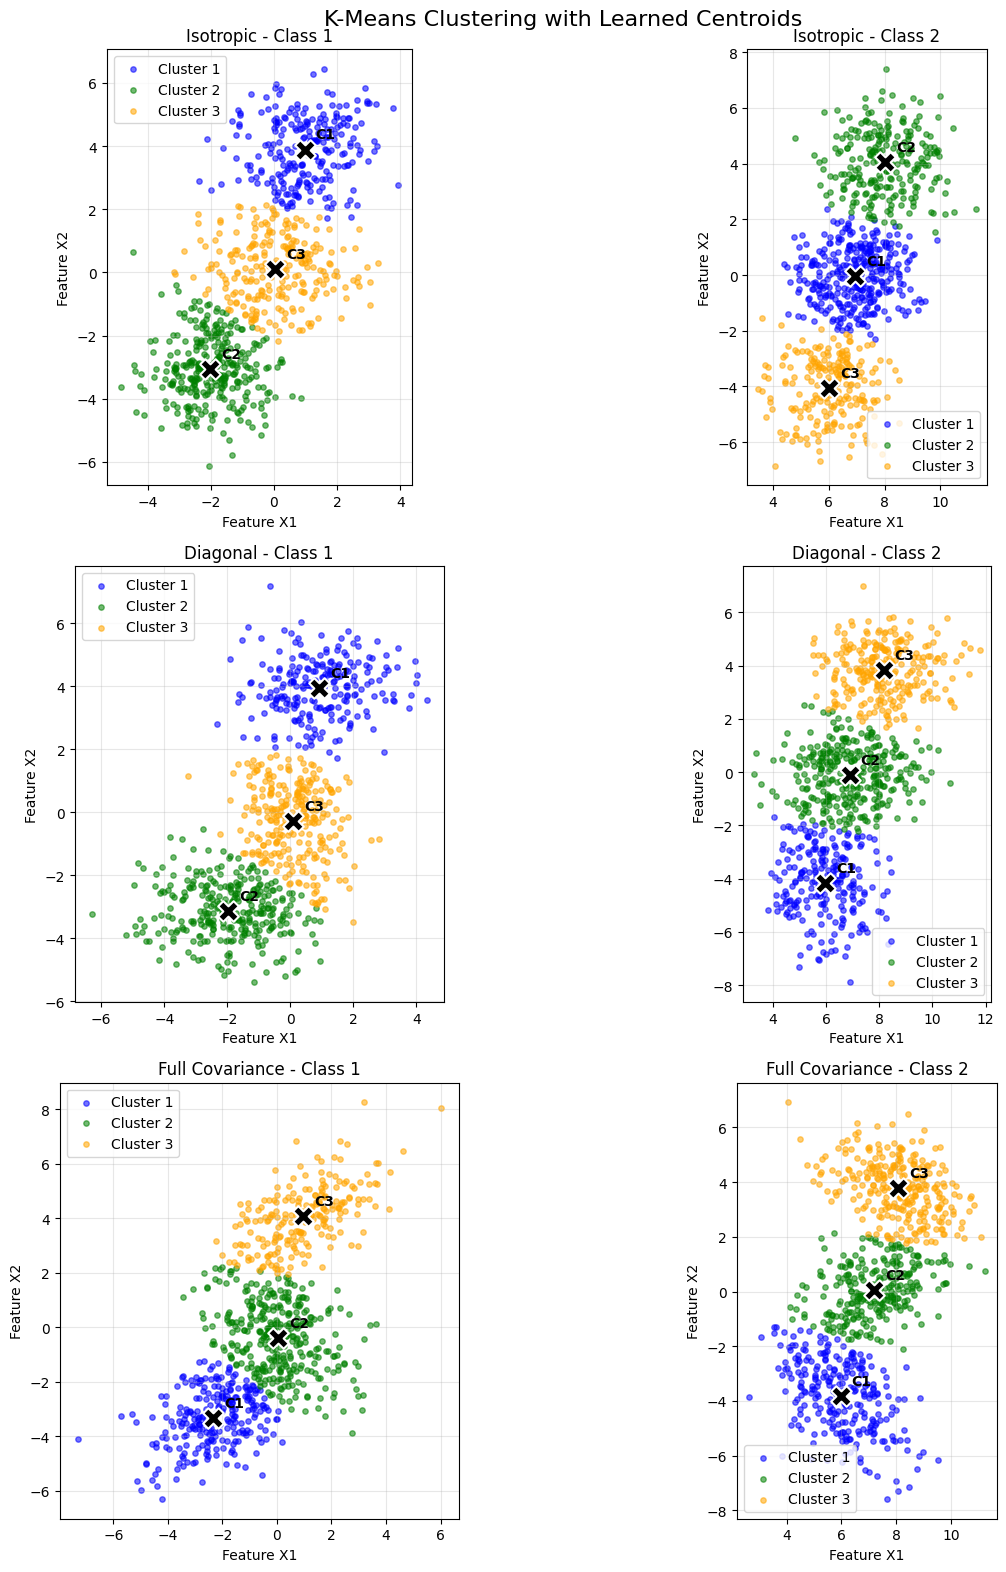

In [ ]:

# Plot K-Means clusters and their learned centroids

kmeans_datasets = [
    ("Isotropic", iso_train1, iso_cluster_labels1, iso_centroids1,
     iso_train2, iso_cluster_labels2, iso_centroids2),

    ("Diagonal", diag_train1, diag_cluster_labels1, diag_centroids1,
     diag_train2, diag_cluster_labels2, diag_centroids2),

    ("Full Covariance", full_train1, full_cluster_labels1, full_centroids1,
     full_train2, full_cluster_labels2, full_centroids2)
]

cluster_colors = ["blue", "green", "orange"]

fig, axes = plt.subplots(3, 2, figsize=(14, 16))

for row, dataset in enumerate(kmeans_datasets):

    name, data1, labels1, centers1, data2, labels2, centers2 = dataset

    class_datasets = [
        (data1, labels1, centers1),
        (data2, labels2, centers2)
    ]

    for col, (data, labels, centers) in enumerate(class_datasets):

        ax = axes[row][col]

        # Plot each K-Means cluster separately
        for cluster_id in range(K):

            cluster_points = [
                data[i]
                for i in range(len(data))
                if labels[i] == cluster_id
            ]

            x = [point[0] for point in cluster_points]
            y = [point[1] for point in cluster_points]

            ax.scatter(
                x, y,
                color=cluster_colors[cluster_id],
                s=15,
                alpha=0.55,
                label="Cluster " + str(cluster_id + 1)
            )

        # Mark centroids with large black X markers
        for i, center in enumerate(centers):

            ax.scatter(
                center[0],
                center[1],
                color="black",
                marker="X",
                s=220,
                edgecolors="white",
                linewidths=1.5,
                zorder=5
            )

            ax.annotate(
                "C" + str(i + 1),
                (center[0], center[1]),
                xytext=(8, 8),
                textcoords="offset points",
                fontsize=10,
                fontweight="bold"
            )

        ax.set_title(name + " - Class " + str(col + 1))
        ax.set_xlabel("Feature X1")
        ax.set_ylabel("Feature X2")
        ax.legend()
        ax.grid(alpha=0.3)
        ax.set_aspect("equal", adjustable="box")

plt.suptitle(
    "K-Means Clustering with Learned Centroids",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [ ]:

# STEP 8: Plot K-Means cluster boundaries
# Uses the manually learned centroids from Step 7

def plot_kmeans_boundaries(ax, data, centroids, title):

    # Determine plotting limits
    all_x = [p[0] for p in data]
    all_y = [p[1] for p in data]

    x_min = min(all_x) - 1.5
    x_max = max(all_x) + 1.5
    y_min = min(all_y) - 1.5
    y_max = max(all_y) + 1.5

    # Create a grid manually
    grid_size = 120

    x_step = (x_max - x_min) / (grid_size - 1)
    y_step = (y_max - y_min) / (grid_size - 1)

    xx = []
    yy = []
    zz = []

    for i in range(grid_size):

        x_row = []
        y_row = []
        z_row = []

        for j in range(grid_size):

            x = x_min + j * x_step
            y = y_min + i * y_step

            distances = [
                euclidean_distance_squared([x, y], c)
                for c in centroids
            ]

            nearest = distances.index(min(distances))

            x_row.append(x)
            y_row.append(y)
            z_row.append(nearest)

        xx.append(x_row)
        yy.append(y_row)
        zz.append(z_row)

    # Draw cluster regions
    ax.contourf(
        xx, yy, zz,
        levels=[-0.5, 0.5, 1.5, 2.5],
        colors=["lightblue", "lightgreen", "moccasin"],
        alpha=0.5
    )

    # Draw boundaries between regions
    ax.contour(
        xx, yy, zz,
        levels=[0.5, 1.5],
        colors="black",
        linewidths=1.5
    )

    cluster_colors = ["blue", "green", "orange"]

    # Plot original training points by assigned cluster
    for k in range(len(centroids)):

        cluster_points = []

        for point in data:

            distances = [
                euclidean_distance_squared(point, c)
                for c in centroids
            ]

            if distances.index(min(distances)) == k:
                cluster_points.append(point)

        ax.scatter(
            [p[0] for p in cluster_points],
            [p[1] for p in cluster_points],
            color=cluster_colors[k],
            s=10,
            alpha=0.55,
            label="Cluster " + str(k + 1)
        )

    # Mark learned centroids
    for k, center in enumerate(centroids):

        ax.scatter(
            center[0],
            center[1],
            marker="X",
            color="black",
            edgecolors="white",
            linewidths=1.5,
            s=230,
            zorder=5
        )

        ax.annotate(
            "C" + str(k + 1),
            (center[0], center[1]),
            xytext=(8, 8),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold"
        )

    ax.set_title(title)
    ax.set_xlabel("Feature X1")
    ax.set_ylabel("Feature X2")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)


print("K-Means boundary plotting function created!")


K-Means boundary plotting function created!


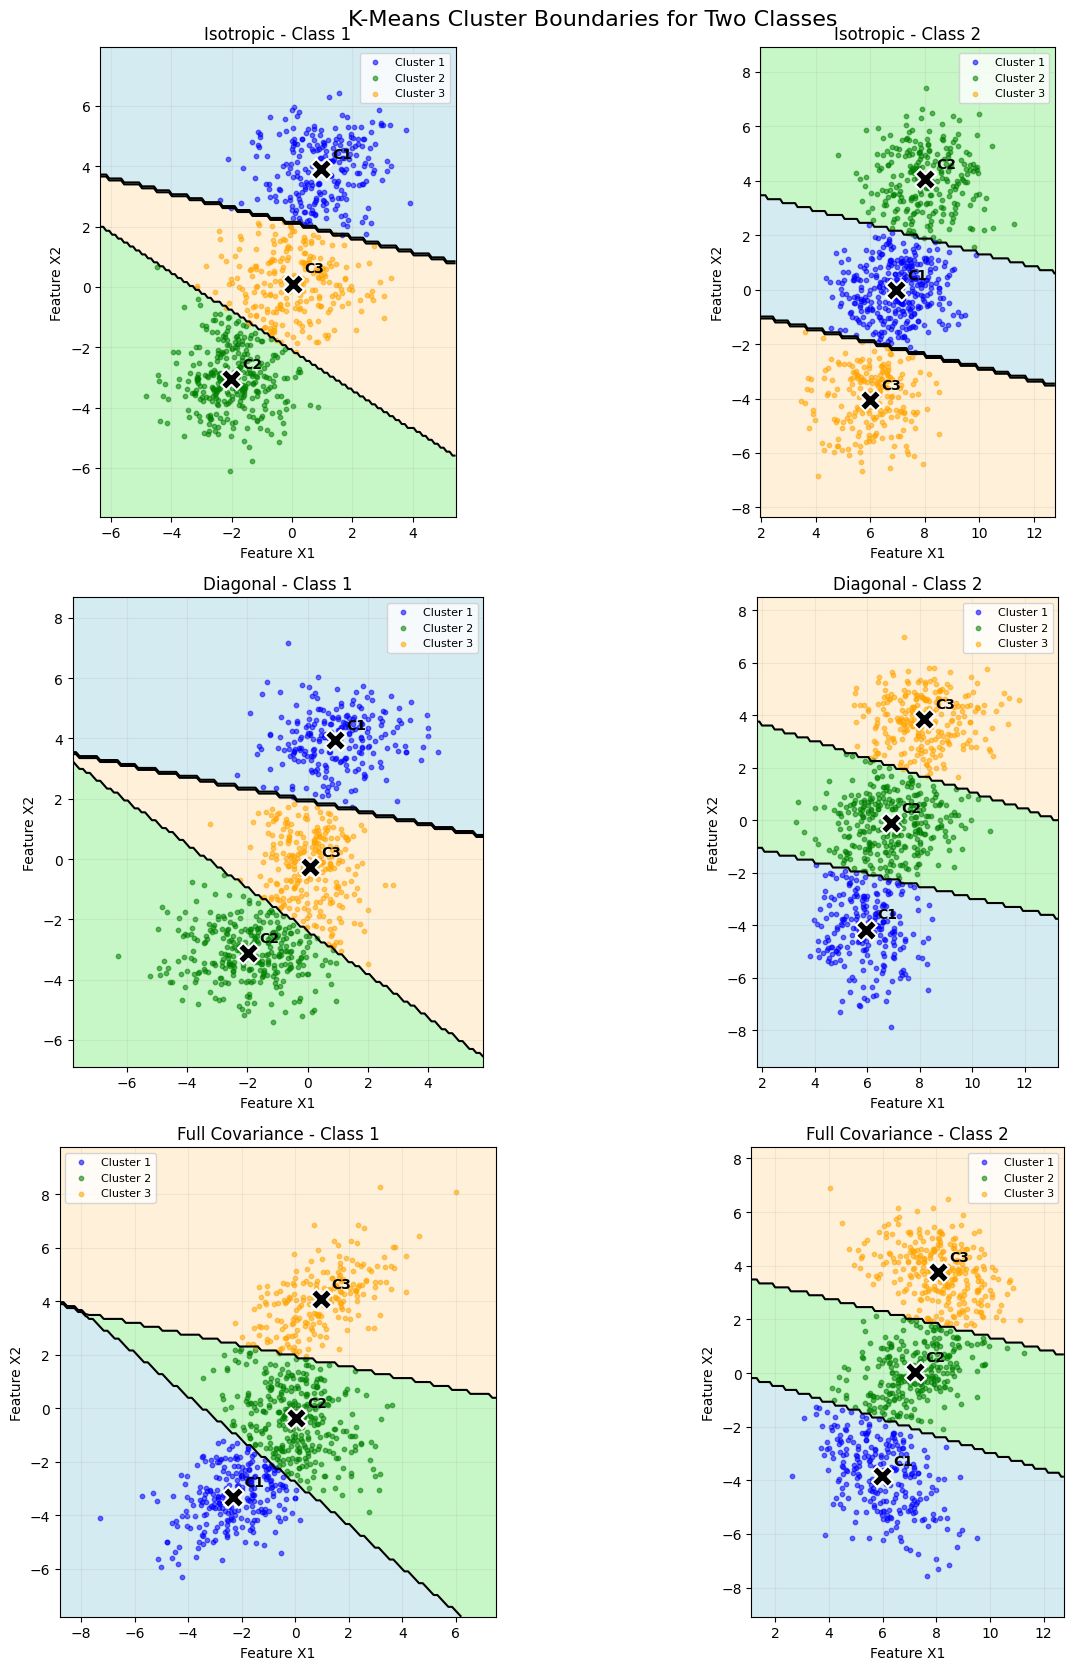

In [ ]:

# STEP 8: Plot boundaries for both classes
# and all three covariance types

boundary_datasets = [
    ("Isotropic", iso_train1, iso_centroids1,
     iso_train2, iso_centroids2),

    ("Diagonal", diag_train1, diag_centroids1,
     diag_train2, diag_centroids2),

    ("Full Covariance", full_train1, full_centroids1,
     full_train2, full_centroids2)
]

fig, axes = plt.subplots(3, 2, figsize=(14, 17))

for row, dataset in enumerate(boundary_datasets):

    name, train1, centers1, train2, centers2 = dataset

    plot_kmeans_boundaries(
        axes[row][0],
        train1,
        centers1,
        name + " - Class 1"
    )

    plot_kmeans_boundaries(
        axes[row][1],
        train2,
        centers2,
        name + " - Class 2"
    )

plt.suptitle(
    "K-Means Cluster Boundaries for Two Classes",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [ ]:

# STEP 9: Classification using minimum K-Means distortion

def classify_using_distortion(point, centroids1, centroids2):

    # Calculate distances to Class 1 centroids
    distances1 = []

    for centroid in centroids1:
        distance = euclidean_distance_squared(point, centroid)
        distances1.append(distance)

    # Calculate distances to Class 2 centroids
    distances2 = []

    for centroid in centroids2:
        distance = euclidean_distance_squared(point, centroid)
        distances2.append(distance)

    # Minimum distortion for each class
    distortion1 = min(distances1)
    distortion2 = min(distances2)

    # Predict the class
    if distortion1 <= distortion2:
        predicted_class = 1
    else:
        predicted_class = 2

    return predicted_class, distortion1, distortion2


# Test classification with one sample
test_point = iso_test1[0]

prediction, d1, d2 = classify_using_distortion(
    test_point,
    iso_centroids1,
    iso_centroids2
)

print("Test Point:", test_point)
print("Actual Class: 1")
print("Predicted Class:", prediction)
print("Class 1 Distortion:", round(d1, 4))
print("Class 2 Distortion:", round(d2, 4))


Test Point: [1.474677885536248, 5.263670510448151]
Actual Class: 1
Predicted Class: 1
Class 1 Distortion: 2.1393
Class 2 Distortion: 44.1424


In [ ]:

# Classify all 20% test samples

def evaluate_classifier(test1, test2, centroids1, centroids2):

    actual_labels = []
    predicted_labels = []

    # Test samples belonging to Class 1
    for point in test1:

        prediction, d1, d2 = classify_using_distortion(
            point, centroids1, centroids2
        )

        actual_labels.append(1)
        predicted_labels.append(prediction)

    # Test samples belonging to Class 2
    for point in test2:

        prediction, d1, d2 = classify_using_distortion(
            point, centroids1, centroids2
        )

        actual_labels.append(2)
        predicted_labels.append(prediction)

    # Calculate correctly classified samples
    correct = 0

    for actual, predicted in zip(actual_labels, predicted_labels):
        if actual == predicted:
            correct += 1

    total = len(actual_labels)
    accuracy = (correct / total) * 100

    return actual_labels, predicted_labels, accuracy


# Isotropic
iso_actual, iso_predicted, iso_accuracy = evaluate_classifier(
    iso_test1, iso_test2,
    iso_centroids1, iso_centroids2
)

# Diagonal
diag_actual, diag_predicted, diag_accuracy = evaluate_classifier(
    diag_test1, diag_test2,
    diag_centroids1, diag_centroids2
)

# Full covariance
full_actual, full_predicted, full_accuracy = evaluate_classifier(
    full_test1, full_test2,
    full_centroids1, full_centroids2
)


print("K-Means Distortion-Based Classification Results")

print("\nIsotropic Accuracy:",
      round(iso_accuracy, 2), "%")

print("Diagonal Accuracy:",
      round(diag_accuracy, 2), "%")

print("Full Covariance Accuracy:",
      round(full_accuracy, 2), "%")


K-Means Distortion-Based Classification Results

Isotropic Accuracy: 100.0 %
Diagonal Accuracy: 99.75 %
Full Covariance Accuracy: 100.0 %


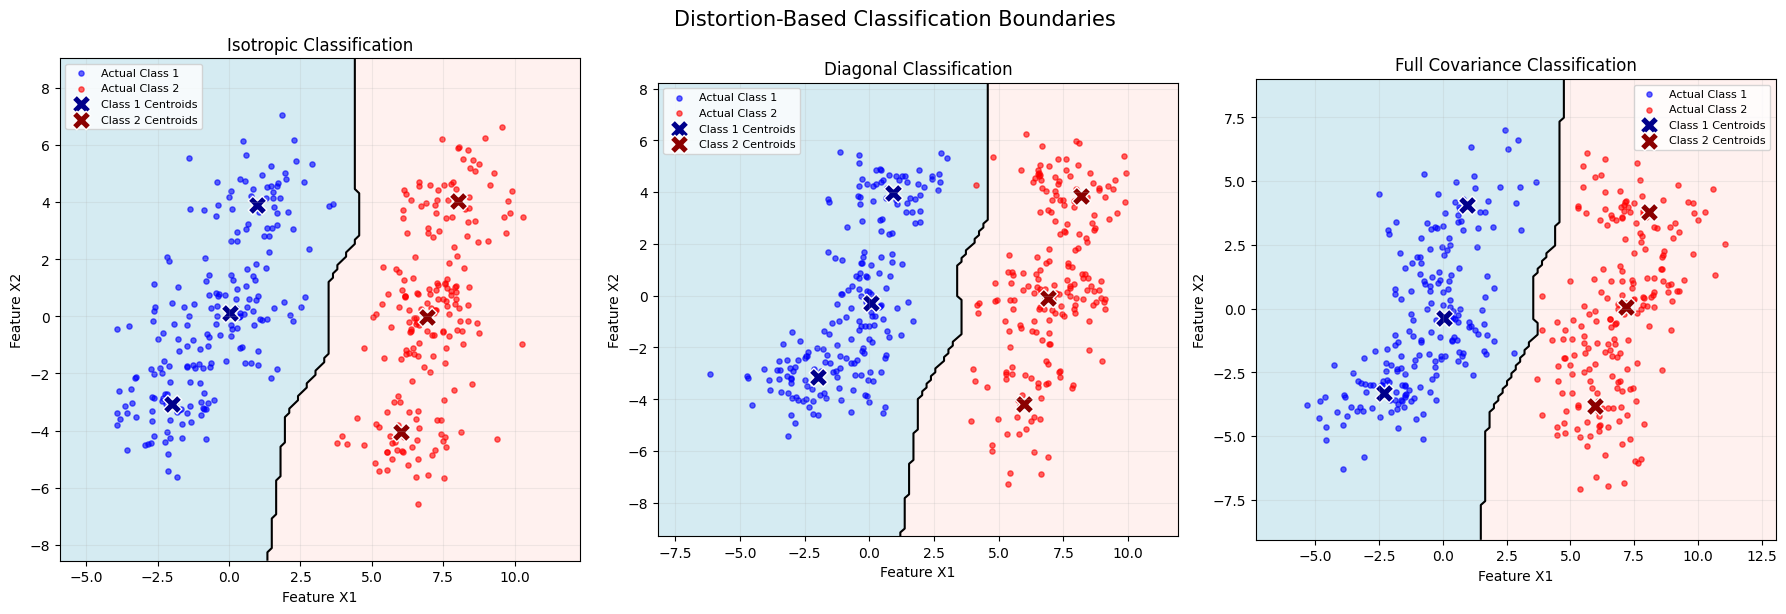

In [ ]:

# STEP 9: Final Class 1 vs Class 2 classification boundaries

classification_datasets = [
    ("Isotropic", iso_test1, iso_test2,
     iso_centroids1, iso_centroids2),

    ("Diagonal", diag_test1, diag_test2,
     diag_centroids1, diag_centroids2),

    ("Full Covariance", full_test1, full_test2,
     full_centroids1, full_centroids2)
]


fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, dataset in zip(axes, classification_datasets):

    name, test1, test2, centers1, centers2 = dataset

    all_points = test1 + test2

    x_min = min(p[0] for p in all_points) - 2
    x_max = max(p[0] for p in all_points) + 2
    y_min = min(p[1] for p in all_points) - 2
    y_max = max(p[1] for p in all_points) + 2

    grid_size = 120

    xx = []
    yy = []
    zz = []

    for i in range(grid_size):

        x_row = []
        y_row = []
        z_row = []

        for j in range(grid_size):

            x = x_min + j * (x_max - x_min) / (grid_size - 1)
            y = y_min + i * (y_max - y_min) / (grid_size - 1)

            prediction, d1, d2 = classify_using_distortion(
                [x, y], centers1, centers2
            )

            x_row.append(x)
            y_row.append(y)
            z_row.append(prediction)

        xx.append(x_row)
        yy.append(y_row)
        zz.append(z_row)

    # Colour classification regions
    ax.contourf(
        xx, yy, zz,
        levels=[0.5, 1.5, 2.5],
        colors=["lightblue", "mistyrose"],
        alpha=0.5
    )

    # Draw decision boundary
    ax.contour(
        xx, yy, zz,
        levels=[1.5],
        colors="black",
        linewidths=1.5
    )

    # Plot actual test samples
    ax.scatter(
        [p[0] for p in test1],
        [p[1] for p in test1],
        color="blue",
        s=14,
        alpha=0.6,
        label="Actual Class 1"
    )

    ax.scatter(
        [p[0] for p in test2],
        [p[1] for p in test2],
        color="red",
        s=14,
        alpha=0.6,
        label="Actual Class 2"
    )

    # Class 1 centroids
    ax.scatter(
        [p[0] for p in centers1],
        [p[1] for p in centers1],
        marker="X",
        s=180,
        color="darkblue",
        edgecolors="white",
        label="Class 1 Centroids"
    )

    # Class 2 centroids
    ax.scatter(
        [p[0] for p in centers2],
        [p[1] for p in centers2],
        marker="X",
        s=180,
        color="darkred",
        edgecolors="white",
        label="Class 2 Centroids"
    )

    ax.set_title(name + " Classification")
    ax.set_xlabel("Feature X1")
    ax.set_ylabel("Feature X2")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

plt.suptitle(
    "Distortion-Based Classification Boundaries",
    fontsize=15
)

plt.tight_layout()
plt.show()


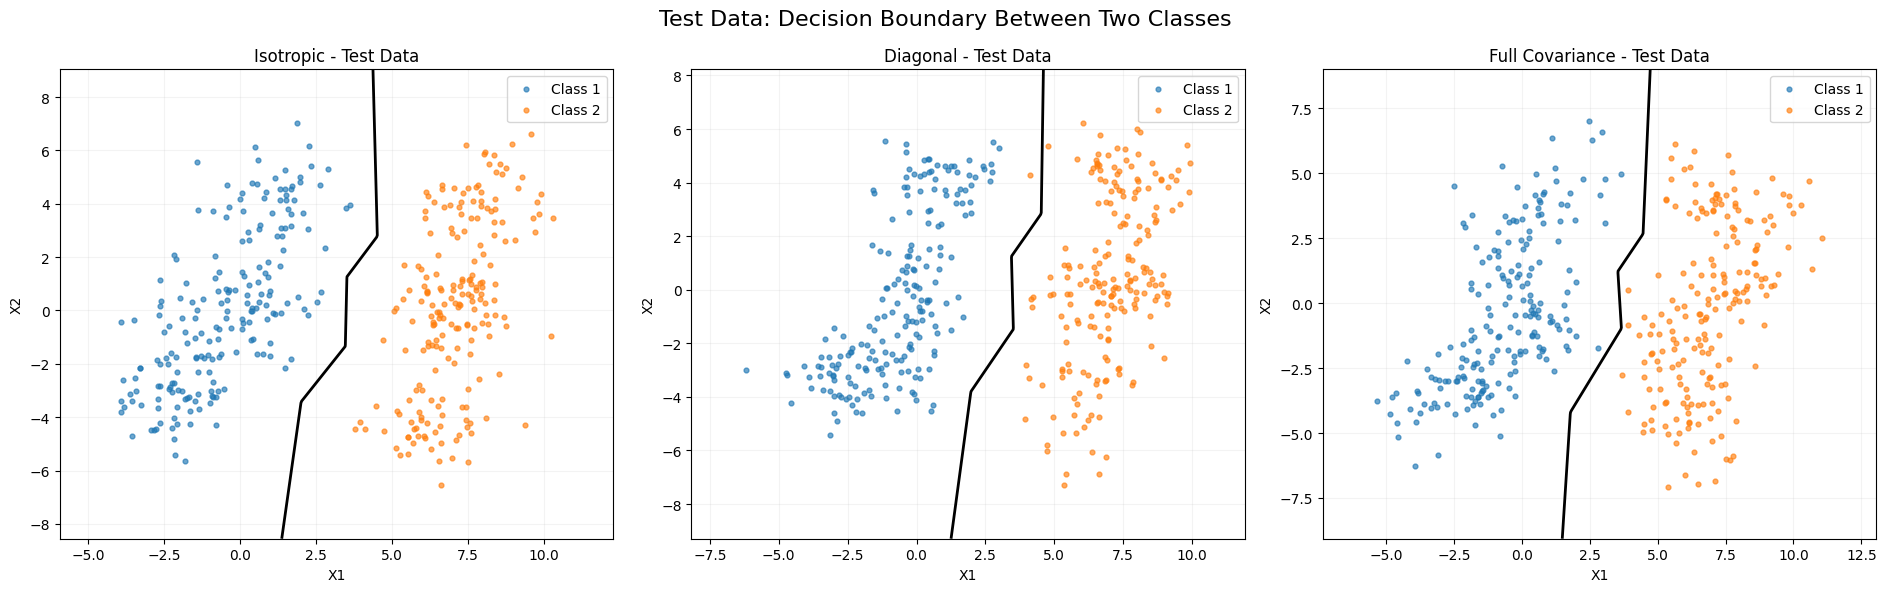

In [ ]:

# CELL 21A: Test Data Decision Boundary Between Two Classes

def plot_two_class_boundary(ax, test1, test2,
                            centroids1, centroids2, title):

    all_points = test1 + test2

    x_min = min(p[0] for p in all_points) - 2
    x_max = max(p[0] for p in all_points) + 2
    y_min = min(p[1] for p in all_points) - 2
    y_max = max(p[1] for p in all_points) + 2

    grid_size = 250

    xx = []
    yy = []
    difference = []

    for i in range(grid_size):

        x_row = []
        y_row = []
        d_row = []

        for j in range(grid_size):

            x = x_min + j * (x_max - x_min) / (grid_size - 1)
            y = y_min + i * (y_max - y_min) / (grid_size - 1)

            prediction, d1, d2 = classify_using_distortion(
                [x, y], centroids1, centroids2
            )

            x_row.append(x)
            y_row.append(y)

            # Zero means equal distortion
            d_row.append(d1 - d2)

        xx.append(x_row)
        yy.append(y_row)
        difference.append(d_row)

    # Draw ONLY the black classification boundary
    ax.contour(
        xx, yy, difference,
        levels=[0],
        colors="black",
        linewidths=2
    )

    # Plot actual Class 1 test samples
    ax.scatter(
        [p[0] for p in test1],
        [p[1] for p in test1],
        color="tab:blue",
        s=12,
        alpha=0.65,
        label="Class 1"
    )

    # Plot actual Class 2 test samples
    ax.scatter(
        [p[0] for p in test2],
        [p[1] for p in test2],
        color="tab:orange",
        s=12,
        alpha=0.65,
        label="Class 2"
    )

    ax.set_title(title)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.legend()
    ax.grid(alpha=0.15)


# Plot all three covariance experiments
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

plot_two_class_boundary(
    axes[0], iso_test1, iso_test2,
    iso_centroids1, iso_centroids2,
    "Isotropic - Test Data"
)

plot_two_class_boundary(
    axes[1], diag_test1, diag_test2,
    diag_centroids1, diag_centroids2,
    "Diagonal - Test Data"
)

plot_two_class_boundary(
    axes[2], full_test1, full_test2,
    full_centroids1, full_centroids2,
    "Full Covariance - Test Data"
)

plt.suptitle(
    "Test Data: Decision Boundary Between Two Classes",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [ ]:

# STEP 10: Final Results Summary

results_summary = [
    ("Isotropic", iso_accuracy,
     iso_distortion1, iso_distortion2,
     iso_iter1, iso_iter2),

    ("Diagonal", diag_accuracy,
     diag_distortion1, diag_distortion2,
     diag_iter1, diag_iter2),

    ("Full Covariance", full_accuracy,
     full_distortion1, full_distortion2,
     full_iter1, full_iter2)
]

print("=" * 90)
print("PRML ASSIGNMENT 6 - FINAL RESULTS")
print("=" * 90)

print(
    f"{'Covariance':<18}"
    f"{'Accuracy (%)':<16}"
    f"{'Class 1 SSE':<17}"
    f"{'Class 2 SSE':<17}"
    f"{'Iterations C1/C2':<20}"
)

print("-" * 90)

for name, accuracy, d1, d2, i1, i2 in results_summary:
    print(
        f"{name:<18}"
        f"{accuracy:<16.2f}"
        f"{d1:<17.2f}"
        f"{d2:<17.2f}"
        f"{str(i1) + '/' + str(i2):<20}"
    )

print("=" * 90)

# Identify the highest test accuracy
best_result = max(results_summary, key=lambda x: x[1])

print("\nHighest Test Accuracy:", best_result[0])
print("Accuracy:", round(best_result[1], 2), "%")


PRML ASSIGNMENT 6 - FINAL RESULTS
Covariance        Accuracy (%)    Class 1 SSE      Class 2 SSE      Iterations C1/C2    
------------------------------------------------------------------------------------------
Isotropic         100.00          1782.71          1797.81          11/9                
Diagonal          99.75           1871.76          2097.07          13/11               
Full Covariance   100.00          2393.87          2226.14          12/14               

Highest Test Accuracy: Isotropic
Accuracy: 100.0 %
